# Quantum Bloom | Introductory Quantum-Kernel Classification
**Integrated lab · 24 October 2026**

**Question:** With the same four PCA inputs, training/validation cases and fixed SVM settings, how do classical RBF and simulated quantum Z and ZZ kernels compare?

**Learning goals:** Follow training-only preprocessing; explain a quantum similarity kernel; run a controlled comparison; distinguish measurements from interpretation.

**Lab route:** Setup → split → development-data EDA → classical references → quantum maps → matched experiment → interpretation and export.

This integrates the group's latest EDA and maroon/gold visual style with the final baseline protocol. The clean teaching copy has no saved execution outputs. Historical figures below are from prior team runs; fresh results are generated by the code.

**Research history:** Earlier demonstrations examined the original 114-case reserved partition. This lab excludes it from EDA and evaluation, but it is not an untouched final test. Z was investigated after weak ZZ performance; results are exploratory. This educational dataset benchmark is not a clinical diagnostic system. Exact simulation does not establish hardware performance or quantum advantage.

**Run:** Open in Colab, run installation first if needed, restart if requested, then run the remaining cells in order. Download the executed notebook and the results ZIP produced at the end. Keep EXP-001 separate from the smaller matched comparison. EXP-004 remains optional in the separate diagnostic notebook.

## 1. Setup and fixed protocol
Run this installation cell in a fresh Colab runtime. The two Qiskit versions match the supplied team environment. Other installed package versions are recorded below; installation is separate from imports so restarting is straightforward.

In [1]:
%pip install -q "qiskit==2.6.1" "qiskit-machine-learning==0.9.1" scikit-learn pandas matplotlib
# Restart the runtime if Colab requests it, then continue below.

In [2]:
import json
import hashlib
import platform
import shutil
from datetime import datetime, timezone
import importlib.metadata as metadata
import time
import sys
import numpy as np
import pandas as pd
import sklearn
import qiskit
import qiskit_machine_learning
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, recall_score, roc_auc_score, confusion_matrix, make_scorer
from qiskit.circuit.library import z_feature_map, zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

SEED, FOLDS, N_TRAIN, N_VAL, N_PCA, C = 42, 5, 80, 40, 4, 1.0
OUT = Path("quantum_bloom_lean_results") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT.mkdir(parents=True, exist_ok=False)
config = {"revision": "integrated-lab-1", "seed": SEED, "folds": FOLDS,
          "outer_test_fraction": 0.20, "matched_train": N_TRAIN, "matched_validation": N_VAL,
          "pca_components": N_PCA, "pca_solver": "full", "angle_range": [0, float(np.pi)],
          "clip": False, "C": C, "rbf_gamma": "scale", "reps": 2,
          "zz_entanglement": "linear", "shots": None, "auto_clear_cache": True,
          "positive_class": "malignant=1", "reserved_partition_previously_examined": True,
          "eda_scope": "development partition only", "hyperparameter_tuning": False}
environment = {"python": sys.version, "platform": platform.platform(),
               "packages": {p: metadata.version(p) for p in
                   ["numpy", "pandas", "scipy", "scikit-learn", "qiskit",
                    "qiskit-machine-learning", "matplotlib"]}}
(OUT / "config.json").write_text(json.dumps(config, indent=2))
(OUT / "environment.json").write_text(json.dumps(environment, indent=2))
print("Python", sys.version.split()[0], "sklearn", sklearn.__version__,
      "Qiskit", qiskit.__version__, "Qiskit ML", qiskit_machine_learning.__version__)

# Meharry Medical College colors: Maroon and Gold
MAROON, GOLD, GRAY = "#5C1D24", "#FFC72C", "#8a8984"      # benign, malignant, neutral
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

Python 3.13.16 sklearn 1.6.1 Qiskit 2.6.1 Qiskit ML 0.9.1


## 2. Load the data and split before inspection
There are **569 cases × 30 numerical cell-nucleus measurements**. Recode malignant as **1**, so malignant recall measures the fraction of malignant cases detected. Preserve the original stratified 80/20 split (seed 42): 455 development cases and 114 reserved cases.

Only the development partition feeds this lab's EDA and experiments. Five parent folds are fixed once and reused. All learned transformations are fitted within training folds, never on validation rows.

In [3]:
data = load_breast_cancer()
X = data.data.copy()
y = (data.target == 0).astype(int)  # Positive class is malignant.
ids = np.arange(len(y))
dev_ids, reserved_ids = train_test_split(
    ids, test_size=0.20, stratify=y, random_state=SEED
)
X_dev, y_dev = X[dev_ids], y[dev_ids]
cv = list(StratifiedKFold(n_splits=FOLDS, shuffle=True,
                          random_state=SEED).split(X_dev, y_dev))
assert X_dev.shape == (455, 30) and len(reserved_ids) == 114
print("Full:", X.shape, "Development:", X_dev.shape,
      "Reserved (not used here):", len(reserved_ids))
print("Development malignant:", y_dev.sum(), "benign:", (y_dev == 0).sum())
assert not np.intersect1d(dev_ids, reserved_ids).size
pd.DataFrame({"row_id": ids, "partition": np.where(np.isin(ids, dev_ids), "development", "reserved")}).to_csv(OUT / "outer_partition.csv", index=False)
data_fingerprint = hashlib.sha256(X.tobytes() + y.tobytes()).hexdigest()
_ = (OUT / "dataset_sha256.txt").write_text(data_fingerprint + "\n")

Full: (569, 30) Development: (455, 30) Reserved (not used here): 114
Development malignant: 170 benign: 285


## 3. Explore development data — group additions
Inspect missingness, class balance, four selected feature distributions, and correlations. These are descriptive plots, not a feature-selection step: the experimental pipeline still uses all 30 measurements before PCA.

The single-feature score is **direction-adjusted apparent AUC**, `max(AUC, 1−AUC)`, on these same development cases. Ranking features and choosing direction using their labels makes it exploratory; it is not cross-validated model performance. Recall and balanced accuracy remain the main classification measures.

In [4]:
feature_names = list(data.feature_names)
df = pd.DataFrame(X_dev, columns=feature_names)
df["malignant"] = y_dev
print("Development measurements:", X_dev.shape, "| missing values:", int(df.isna().sum().sum()))
display(df.head())
counts = df["malignant"].value_counts().reindex([0, 1]).rename({0: "benign", 1: "malignant"})
display(pd.DataFrame({"count": counts, "share": counts / len(df)}).round(3))

Development measurements: (455, 30) | missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,...,33.88,123.80,1150.0,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452,1
1,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,...,15.64,86.97,549.1,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771,0
2,12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,...,27.01,91.63,645.8,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151,0
3,14.90,22.53,102.10,685.0,0.09947,0.22250,0.27330,0.09711,0.2041,0.06898,...,27.57,125.40,832.7,0.14190,0.7090,0.9019,0.24750,0.2866,0.11550,1
4,18.61,20.25,122.10,1094.0,0.09440,0.10660,0.14900,0.07731,0.1697,0.05699,...,27.26,139.90,1403.0,0.13380,0.2117,0.3446,0.14900,0.2341,0.07421,1


,count,share
malignant,,
benign,285,0.626
malignant,170,0.374


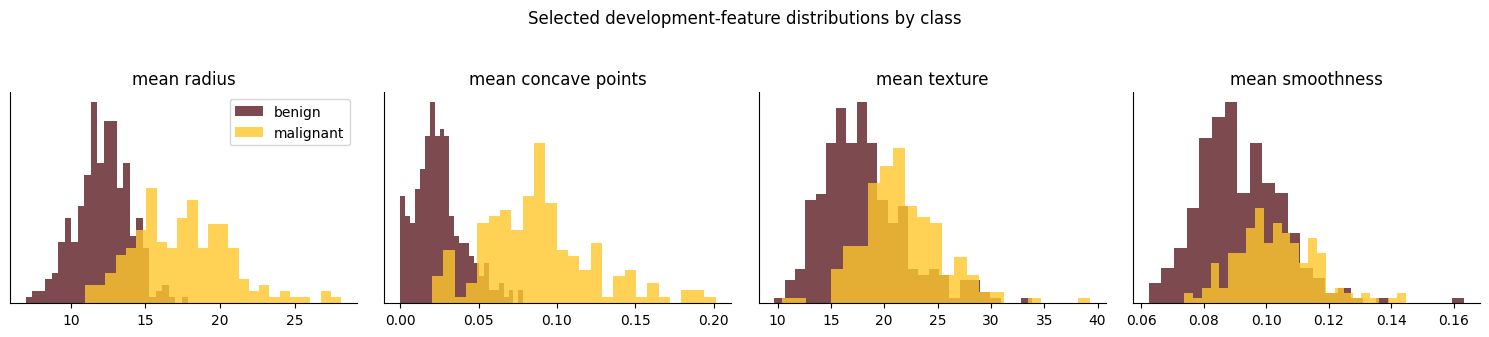

Top apparent single-feature AUCs (development data):


,apparent_direction_adjusted_AUC
worst perimeter,0.974
worst radius,0.969
worst area,0.968
mean concave points,0.964
worst concave points,0.963


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, f in zip(axes, ["mean radius", "mean concave points", "mean texture", "mean smoothness"]):
    for label, color, name in [(0, MAROON, "benign"), (1, GOLD, "malignant")]:
        ax.hist(df.loc[df.malignant == label, f], bins=25, alpha=0.8, color=color, label=name)
    ax.set_title(f); ax.set_yticks([])
axes[0].legend()
plt.suptitle("Selected development-feature distributions by class", y=1.04)
plt.tight_layout()
plt.savefig(OUT / "eda_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

# Descriptive, direction-adjusted AUC on the development data; not validation performance.
single = {f: roc_auc_score(df.malignant, df[f]) for f in feature_names}
single = pd.Series({f: max(a, 1 - a) for f, a in single.items()}).sort_values(ascending=False)
print("Top apparent single-feature AUCs (development data):"); display(single.head(5).round(3).to_frame("apparent_direction_adjusted_AUC"))

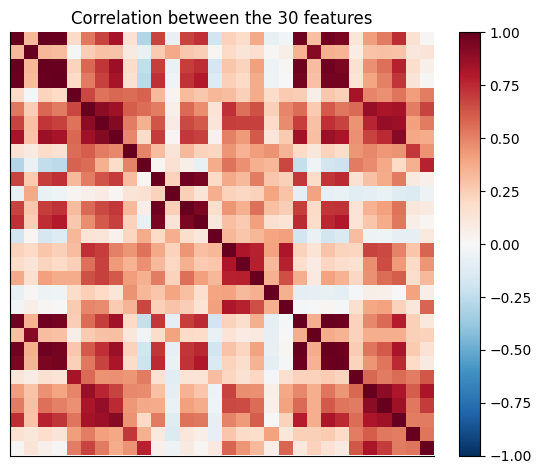

21 development-feature pairs have |correlation| > 0.9.


In [6]:
corr = df[feature_names].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("Correlation between the 30 features")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.savefig(OUT / "eda_correlations.png", dpi=180, bbox_inches="tight")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
n_pairs = int((upper.abs() > 0.9).sum().sum())
print(f"{n_pairs} development-feature pairs have |correlation| > 0.9.")
corr.to_csv(OUT / "development_feature_correlations.csv")

**Read the EDA carefully:** No missing values means no imputation is needed here; it does not establish overall data quality. Class imbalance motivates stratification and balanced accuracy. Correlation suggests redundancy, while PCA measures retained variance directly; redundancy alone does not guarantee preserved class information.

For **these feature maps**, four inputs use four qubits. Other encodings can use different input-to-qubit mappings. Four-qubit statevectors are inexpensive to simulate; statevector storage grows exponentially with qubit count.

## 4 — EXP-001: classical reference models
Before the quantum comparison, establish what ordinary classifiers achieve using **all 30 measurements** versus **four PCA components**. `Pipeline` fits scaling and PCA independently inside each CV training fold, preventing validation-data leakage. These reference folds train on **364 observations** each and are **not** the direct 80-case quantum comparator.

In [7]:
classical = {
    "Logistic / 30": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, max_iter=5000, random_state=SEED))]),
    "RBF / 30": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", C=C, gamma="scale"))]),
    "RBF / PCA4": Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=N_PCA, svd_solver="full")),
        ("angle", MinMaxScaler(feature_range=(0, np.pi))),
        ("model", SVC(kernel="rbf", C=C, gamma="scale"))]),
}
scorers = {"balanced_accuracy": "balanced_accuracy",
           "malignant_recall": make_scorer(recall_score, pos_label=1),
           "roc_auc": "roc_auc"}
reference_rows = []
for name, model in classical.items():
    scores = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scorers, n_jobs=1, error_score="raise")
    for i in range(FOLDS):
        reference_rows.append({"fold": i+1, "model": name,
            **{k: scores["test_"+k][i] for k in scorers}})
reference = pd.DataFrame(reference_rows)
print("EXP-001: full development-fold reference (mean ± fold SD)")
display(reference.groupby("model", sort=False)[list(scorers)].agg(["mean", "std"]).round(4))

EXP-001: full development-fold reference (mean ± fold SD)


balanced_accuracy         malignant_recall         roc_auc  \
                           mean     std             mean     std    mean   
model                                                                      
Logistic / 30            0.9695  0.0209           0.9529  0.0446  0.9958   
RBF / 30                 0.9665  0.0123           0.9471  0.0383  0.9949   
RBF / PCA4               0.9571  0.0080           0.9353  0.0246  0.9927   

                       
                  std  
model                  
Logistic / 30  0.0052  
RBF / 30       0.0056  
RBF / PCA4     0.0057

## 5 — Feature maps and reusable scoring
The **Z** feature map encodes four PCA scores using single-qubit operations; **ZZ** includes additional two-qubit interactions. Both use **four qubits and two repetitions**. A fidelity kernel computes squared quantum-state overlaps as sample-to-sample similarities. The classical SVM then learns from these similarities. Changing the feature map changes more than entanglement alone; this is an encoding-design comparison, not an isolation of entanglement.

For each pair of examples, the quantum kernel is

$$K(x,z)=|\langle\phi(x)|\phi(z)\rangle|^2.$$

Encoding produces simulated quantum states; their squared overlaps form a similarity matrix. A **classical SVM** learns from that matrix. `shots=None` means exact fidelity in simulation, without finite-shot sampling or device noise.

In [8]:
maps = {
    "Quantum Z": z_feature_map(feature_dimension=N_PCA, reps=2),
    "Quantum ZZ": zz_feature_map(feature_dimension=N_PCA, reps=2,
                                 entanglement="linear"),
}
for name, fmap in maps.items():
    assert fmap.num_qubits == N_PCA and fmap.num_parameters == N_PCA
    print(name, "qubits:", fmap.num_qubits, "depth:", fmap.depth())

def metrics(y_true, preds, scores):
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {"balanced_accuracy": balanced_accuracy_score(y_true, preds),
            "malignant_recall": recall_score(y_true, preds, pos_label=1),
            "roc_auc": roc_auc_score(y_true, scores),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

Quantum Z qubits: 4 depth: 4
Quantum ZZ qubits: 4 depth: 19


## 6 — EXP-002C / EXP-003: matched five-fold comparison
**Key experimental control:** For each of the same five parent folds, take a seeded stratified subset of **80 training and 40 validation observations**. Learn `StandardScaler → PCA(4) → angle scaling [0, π]` using the 80 training rows only; transform the 40 validation rows without refitting. **All three models use identical transformed rows and labels.** The RBF uses its usual similarity formula; each quantum kernel uses an exact statevector simulation (`shots=None`). Validate the quantum train matrix before SVM fitting. Timing covers kernel generation and SVM fit/prediction, not shared preprocessing or numerical diagnostics.

**Protocol:** There is no tuning. Validation angles may fall outside `[0, π]` because the training-fitted scaler uses `clip=False`; preserve that behavior. Each model uses the same row order. Training kernel checks cover shape, finite values, symmetry, unit diagonal, fidelity bounds and positive semidefiniteness. These checks test numerical consistency, not predictive validity.

Compute + fit/predict timing excludes shared preprocessing and numerical checks. It is descriptive local runtime, not a speedup claim. The five-fold training subsets overlap across folds.

In [9]:
matched_rows, variance_rows, feature_rows = [], [], []
membership_rows, prediction_rows, diagnostic_rows = [], [], []
for fold, (itr, iva) in enumerate(cv, start=1):
    # Reuse the historical seeded 80/40 sample-selection protocol.
    itr, _ = train_test_split(itr, train_size=N_TRAIN,
                              stratify=y_dev[itr], random_state=SEED)
    iva, _ = train_test_split(iva, train_size=N_VAL,
                              stratify=y_dev[iva], random_state=SEED)
    xtr, xva = X_dev[itr], X_dev[iva]
    ytr, yva = y_dev[itr], y_dev[iva]
    assert not np.intersect1d(itr, iva).size

    for role, selected in [("train", itr), ("validation", iva)]:
        for position, local_id in enumerate(selected):
            membership_rows.append({"fold": fold, "role": role, "position": position,
                                    "row_id": int(dev_ids[local_id]), "label": int(y_dev[local_id])})
    assert not np.intersect1d(dev_ids[np.r_[itr, iva]], reserved_ids).size

    # Training-only transformations prevent validation leakage.
    prep = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=N_PCA, svd_solver="full")),
        ("angles", MinMaxScaler(feature_range=(0, np.pi), clip=False))])
    atr = prep.fit_transform(xtr)
    ava = prep.transform(xva)
    pca = prep.named_steps["pca"]
    np.savez_compressed(OUT / f"fold_{fold}_preprocessing.npz",
        train_angles=atr, validation_angles=ava, components=pca.components_,
        variance_ratio=pca.explained_variance_ratio_, pca_mean=pca.mean_,
        standard_mean=prep.named_steps["scale"].mean_, standard_scale=prep.named_steps["scale"].scale_,
        angle_scale=prep.named_steps["angles"].scale_, angle_offset=prep.named_steps["angles"].min_)
    variance_rows.append({"fold": fold,
                          "variance_retained": pca.explained_variance_ratio_.sum(),
                          "validation_angles_outside_training_range": int(((ava < 0) | (ava > np.pi)).sum())})
    if fold == 1:
        for k, weights in enumerate(pca.components_, start=1):
            leading = np.argsort(np.abs(weights))[-5:][::-1]
            for j in leading:
                feature_rows.append({"component": f"PC{k}",
                                     "original_measurement": data.feature_names[j],
                                     "coefficient": weights[j]})

    # Same 80/40 rows and same PCA angles for all three classifiers.
    for name in ["Classical RBF", "Quantum Z", "Quantum ZZ"]:
        diagnostic_seconds = 0.0
        t0 = time.perf_counter()
        if name == "Classical RBF":
            train_input, val_input = atr, ava
            model = SVC(kernel="rbf", C=C, gamma="scale")
        else:
            kernel = FidelityStatevectorKernel(feature_map=maps[name],
                                                shots=None, auto_clear_cache=True)
            train_input = kernel.evaluate(x_vec=atr)
            val_input = kernel.evaluate(x_vec=ava, y_vec=atr)
            # Validate numerical consistency separately from model timing.
            diagnostics_start = time.perf_counter()
            K = train_input
            assert K.shape == (N_TRAIN, N_TRAIN) and val_input.shape == (N_VAL, N_TRAIN)
            assert np.isfinite(K).all() and np.isfinite(val_input).all()
            assert np.allclose(K, K.T, atol=1e-8, rtol=0)
            assert np.allclose(np.diag(K), 1, atol=1e-8, rtol=0)
            assert K.min() >= -1e-8 and K.max() <= 1 + 1e-8
            assert val_input.min() >= -1e-8 and val_input.max() <= 1 + 1e-8
            min_eigenvalue = float(np.linalg.eigvalsh(K).min())
            assert min_eigenvalue >= -1e-7
            # Save outside the timing interval below.
            diagnostic_rows.append({"fold": fold, "model": name,
                "min_eigenvalue": min_eigenvalue, "symmetry_max_error": float(np.abs(K-K.T).max()),
                "diagonal_max_error": float(np.abs(np.diag(K)-1).max()),
                "diagnostic_seconds": diagnostic_seconds})
            diagnostic_seconds = time.perf_counter() - diagnostics_start
            diagnostic_rows[-1]["diagnostic_seconds"] = diagnostic_seconds
            model = SVC(kernel="precomputed", C=C)
        model.fit(train_input, ytr)
        pred = model.predict(val_input)
        score = model.decision_function(val_input)
        elapsed = time.perf_counter() - t0 - diagnostic_seconds
        if name != "Classical RBF":
            np.savez_compressed(OUT / f"fold_{fold}_{name.replace(' ', '_')}_kernels.npz",
                                train=train_input, validation=val_input)
        for row_id, label, prediction, decision in zip(dev_ids[iva], yva, pred, score):
            prediction_rows.append({"fold": fold, "model": name, "row_id": int(row_id),
                "label": int(label), "prediction": int(prediction), "decision_score": float(decision)})
        matched_rows.append({"fold": fold, "model": name,
                             **metrics(yva, pred, score), "runtime_seconds": elapsed})
    print(f"Fold {fold}/{FOLDS} complete")

matched = pd.DataFrame(matched_rows)
print("EXP-002C / EXP-003: matched 80/40 results (mean ± fold SD)")
cols = ["balanced_accuracy", "malignant_recall", "roc_auc", "runtime_seconds"]
display(matched.groupby("model", sort=False)[cols].agg(["mean", "std"]).round(4))

Fold 1/5 complete
Fold 2/5 complete
Fold 3/5 complete
Fold 4/5 complete
Fold 5/5 complete
EXP-002C / EXP-003: matched 80/40 results (mean ± fold SD)


balanced_accuracy         malignant_recall         roc_auc  \
                           mean     std             mean     std    mean   
model                                                                      
Classical RBF            0.9533  0.0380           0.9067  0.0760  0.9877   
Quantum Z                0.8880  0.0597           0.8000  0.1054  0.9387   
Quantum ZZ               0.6133  0.1292           0.3067  0.2385  0.7371   

                      runtime_seconds          
                  std            mean     std  
model                                          
Classical RBF  0.0167          0.0069  0.0055  
Quantum Z      0.0626          0.9668  0.3435  
Quantum ZZ     0.1080          1.3474  0.3232

## 7 — Explain PCA, visualize findings, and export
**PCA creates four weighted combinations** of the original 30 measurements; it does **not randomly select four original features**. Its explained variance is **not predictive accuracy**. Report the three matched models together, while keeping EXP-001 separate. Report fold-to-fold variability, the unoptimized shared `C=1`, the small samples, exact simulation and earlier test exposure.

**Interpret the scores:** Balanced accuracy averages malignant recall and benign recall. Malignant recall counts detected malignant cases divided by all malignant validation cases. ROC AUC measures ranking from decision scores, not calibrated probabilities. A fold SD is descriptive variability, not a confidence interval.

Average four-component PCA variance retained across small training subsets: 82.08%
Fold 1: top coefficients by absolute magnitude (descriptive, not feature importance)


,component,original_measurement,coefficient
0,PC1,mean concave points,0.2518
1,PC1,mean concavity,0.2484
2,PC1,worst concave points,0.2372
3,PC1,mean compactness,0.2365
4,PC1,worst concavity,0.2302
5,PC2,mean fractal dimension,0.3727
6,PC2,fractal dimension error,0.2791
7,PC2,worst fractal dimension,0.2592
8,PC2,mean smoothness,0.2591
9,PC2,symmetry error,0.2473


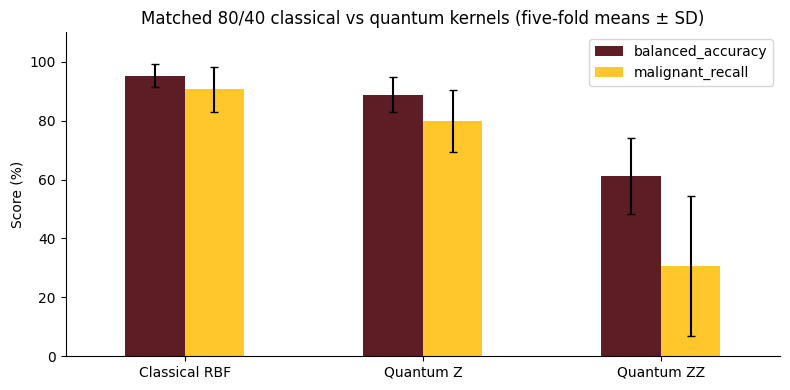

Fresh run versus prior team observations (investigate material differences):


,prior_team_balanced_accuracy_rounded,current_run_balanced_accuracy,difference_from_rounded_history
Classical RBF,0.9533,0.9533,0.0
Quantum Z,0.8880,0.8880,-0.0
Quantum ZZ,0.6133,0.6133,0.0


Artifacts saved to: /content/quantum_bloom_lean_results/20261024T200741_097350Z
Download the results ZIP and this executed notebook:


/content/quantum_bloom_lean_results/20261024T200741_097350Z.zip

In [10]:
print("Average four-component PCA variance retained across small training subsets:",
      f"{pd.DataFrame(variance_rows).variance_retained.mean():.2%}")
print("Fold 1: top coefficients by absolute magnitude (descriptive, not feature importance)")
display(pd.DataFrame(feature_rows).round(4))

means = matched.groupby("model", sort=False)[["balanced_accuracy", "malignant_recall"]].mean()*100
stds = matched.groupby("model", sort=False)[["balanced_accuracy", "malignant_recall"]].std()*100
ax = means.plot.bar(color=[MAROON, GOLD], yerr=stds, capsize=3, figsize=(8, 4), rot=0)
ax.set_title("Matched 80/40 classical vs quantum kernels (five-fold means ± SD)")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 110)
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(OUT / "comparison.png", dpi=180, bbox_inches="tight")
plt.show()
reference.to_csv(OUT / "EXP-001_reference_folds.csv", index=False)
matched.to_csv(OUT / "matched_model_folds.csv", index=False)
pd.DataFrame(variance_rows).to_csv(OUT / "pca_variance_folds.csv", index=False)
pd.DataFrame(feature_rows).to_csv(OUT / "fold1_pca_contributors.csv", index=False)
pd.DataFrame(membership_rows).to_csv(OUT / "matched_membership.csv", index=False)
pd.DataFrame(prediction_rows).to_csv(OUT / "matched_predictions.csv", index=False)
pd.DataFrame(diagnostic_rows).to_csv(OUT / "kernel_diagnostics.csv", index=False)
summary = matched.groupby("model", sort=False)[cols].agg(["mean", "std"])
summary.to_csv(OUT / "matched_summary.csv")
validation_ids = pd.DataFrame(membership_rows).query("role == 'validation'").row_id
assert len(validation_ids) == FOLDS * N_VAL and validation_ids.nunique() == FOLDS * N_VAL
assert len(prediction_rows) == FOLDS * N_VAL * 3

# A reference comparison, not an assertion that values must agree across environments.
historical = pd.Series({"Classical RBF": 0.9533, "Quantum Z": 0.8880, "Quantum ZZ": 0.6133})
check = pd.DataFrame({"prior_team_balanced_accuracy_rounded": historical,
                      "current_run_balanced_accuracy": matched.groupby("model").balanced_accuracy.mean()})
check["difference_from_rounded_history"] = check.current_run_balanced_accuracy - check.prior_team_balanced_accuracy_rounded
print("Fresh run versus prior team observations (investigate material differences):")
display(check.round(4))
check.to_csv(OUT / "history_comparison.csv")
(OUT / "run_status.json").write_text(json.dumps({"status": "completed", "models": 3, "folds": FOLDS,
    "matched_predictions": len(prediction_rows), "distinct_validation_cases": int(validation_ids.nunique())}, indent=2))
archive = shutil.make_archive(str(OUT), "zip", root_dir=OUT)
print("Artifacts saved to:", OUT.resolve())
print("Download the results ZIP and this executed notebook:")
from IPython.display import FileLink
display(FileLink(archive))

## 8. Close the research loop
**Prior team observations (not generated by this clean copy):** In the matched **80 training / 40 validation** design, mean balanced accuracy was **95.33% RBF, 88.80% Z, 61.33% ZZ**. Mean malignant recall was **90.67%, 80.00%, 30.67%**. Use this run's tables to describe reproduced results.

**Supported interpretation of prior results:** Under these fixed settings, RBF had the highest mean performance and Z exceeded ZZ. This comparison does not isolate entanglement as the cause. PCA variance (~82.08% historically for the 80-case subsets) is not classification accuracy; it differs from the 79.32% full-development fit.

**Lab discussion:**
1. Which results are directly comparable, and why is EXP-001 separate?
2. How would a false negative change malignant recall?
3. What changes between Z and ZZ, and what remains controlled?
4. What evidence would be needed to explain weak ZZ performance?

**Limitations:** Small matched subsets, overlapping training folds, exploratory design after prior observations, previously examined reserved partition, fixed untuned `C=1`, one dataset, and noiseless exact simulation. Equal C is not necessarily optimal for each kernel. Neither clinical effectiveness nor general quantum superiority follows.

**Next work, outside this frozen lab:** EXP-004 kernel diagnostics, controlled angle-scale comparisons, training-only tuning with nested evaluation, or new external untouched data. Do not add these experiments to the introductory acceptance run without recording a protocol revision.

**AI assistance:** ChatGPT assisted integration, explanations, bug correction, and export/validation code. Group-origin EDA and plots were retained with documented scope and wording changes. Human team review and fresh Colab execution remain required before submission. See `INTEGRATION_RECORD.md` for the source/change map and local validation scope.

## 9. Optional extension: run the quantum kernels on IBM hardware
Everything above used exact simulation (`shots=None`, no noise). This optional section asks the next question: **what happens when the kernel entries are measured on a real IBM quantum computer?** It follows the hardware recipe from the QML lecture (Part 7). Only three things change from the simulated pipeline:

1. Pick a **backend** (a real device, or a noisy local copy of one).
2. **Transpile** for that device: rewrite the circuit in its native gates and map it onto physical qubits.
3. Replace the exact `FidelityStatevectorKernel` with `FidelityQuantumKernel` driven by the runtime **`SamplerV2`**. Each kernel entry is then the fraction of shots returning `0000` in a *compute-uncompute* circuit $U^\dagger(z)U(x)|0000\rangle$.

**This section is separate from the frozen protocol above.** It does not change Sections 1-8 or any of their results.

**Safe by default.** `HW_MODE = "fake"` runs a *noisy simulator of a real IBM device* locally. It is free, needs no account, and lets you test the whole section. Set `HW_MODE = "ibm"` only when you are ready to spend QPU time; the free Open Plan has a small monthly QPU allowance (check your account), so keep the subset tiny.

**What is compared** (same fold-1 rows, same PCA angles, same `C=1` for every model): classical RBF; exact quantum kernel; quantum kernel measured with finite shots on the device. Beyond accuracy we compare the **kernel matrices** themselves, which is where hardware noise shows up first.

**Read it honestly:** with ~10 validation cases, accuracy and AUC are very coarse (one case is 10 percentage points). The reliable measurement here is how far the hardware kernel is from the exact kernel; the classification scores are a demonstration, not a benchmark.

In [ ]:
%pip install -q "qiskit-ibm-runtime==0.51.0" "qiskit-aer==0.18.0"
# Versions tested with the pinned Qiskit 2.6.1 above. Restart the runtime only if Colab requests it.
# (qiskit-ibm-runtime 0.51 marks SamplerV2 as deprecated and prints a warning; it still works.)

In [ ]:
from getpass import getpass
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute

# ---- Settings you may change --------------------------------------------------------------
HW_MODE = "fake"        # "fake": noisy local simulator of an IBM device (free)   |   "ibm": real QPU
HW_BACKEND_NAME = None  # e.g. "ibm_fez" or "ibm_kingston"; None -> least busy device (ibm mode)
HW_FAKE_DEVICE = "FakeFez"  # which device the noisy simulator imitates (fake mode)
HW_N_TRAIN, HW_N_VAL = 20, 10   # subset of the fold-1 matched rows; circuits grow ~ N^2
HW_SHOTS = 1000                 # shots per circuit
HW_OPT_LEVEL = 3                # transpiler optimization level (lecture setting)
# -------------------------------------------------------------------------------------------

if HW_MODE == "ibm":
    try:                                    # uses an account saved earlier with save_account(...)
        service = QiskitRuntimeService()
    except Exception:                       # otherwise ask; the key is typed, never stored in the notebook
        service = QiskitRuntimeService(channel="ibm_quantum_platform",
                                       token=getpass("IBM Quantum API key: "),
                                       instance=getpass("Instance CRN (blank = default): ") or None)
    hw_backend = (service.backend(HW_BACKEND_NAME) if HW_BACKEND_NAME else
                  service.least_busy(operational=True, simulator=False, min_num_qubits=N_PCA))
else:
    import qiskit_ibm_runtime.fake_provider as fake_provider
    hw_backend = getattr(fake_provider, HW_FAKE_DEVICE)()

hw_pm = generate_preset_pass_manager(optimization_level=HW_OPT_LEVEL, backend=hw_backend)
hw_sampler = SamplerV2(mode=hw_backend)
hw_sampler.options.default_shots = HW_SHOTS
print(f"mode={HW_MODE}  backend={hw_backend.name}  qubits={hw_backend.num_qubits}  shots/circuit={HW_SHOTS}")

### 9.1 Same rows, small subset
Reuse the **fold-1 preprocessing and membership files** already saved by Section 6, then take a stratified `HW_N_TRAIN`/`HW_N_VAL` subset of those 80/40 rows. Nothing is refitted, so the quantum inputs are exactly the PCA angles used in the simulated comparison. The circuit count printed below is the real cost driver.

In [ ]:
hw_pre = np.load(OUT / "fold_1_preprocessing.npz")
mem1 = pd.DataFrame(membership_rows).query("fold == 1")
y_tr1 = mem1.query("role == 'train'").sort_values("position").label.to_numpy()
y_va1 = mem1.query("role == 'validation'").sort_values("position").label.to_numpy()
a_tr1, a_va1 = hw_pre["train_angles"], hw_pre["validation_angles"]
assert len(y_tr1) == len(a_tr1) == N_TRAIN and len(y_va1) == len(a_va1) == N_VAL

i_tr, _ = train_test_split(np.arange(N_TRAIN), train_size=HW_N_TRAIN, stratify=y_tr1, random_state=SEED)
i_va, _ = train_test_split(np.arange(N_VAL), train_size=HW_N_VAL, stratify=y_va1, random_state=SEED)
hw_atr, hw_ytr = a_tr1[i_tr], y_tr1[i_tr]
hw_ava, hw_yva = a_va1[i_va], y_va1[i_va]

n_circuits = HW_N_TRAIN * (HW_N_TRAIN - 1) // 2 + HW_N_VAL * HW_N_TRAIN   # per feature map
print(f"train {HW_N_TRAIN} ({hw_ytr.sum()} malignant) | validation {HW_N_VAL} ({hw_yva.sum()} malignant)")
print(f"circuits per feature map: {n_circuits}  ->  both maps: {2 * n_circuits} circuits, {2 * n_circuits * HW_SHOTS:,} shots")

# Exact references on the identical rows.
hw_exact = {}
for name in ["Quantum Z", "Quantum ZZ"]:
    k = FidelityStatevectorKernel(feature_map=maps[name], shots=None, auto_clear_cache=True)
    hw_exact[name] = (k.evaluate(x_vec=hw_atr), k.evaluate(x_vec=hw_ava, y_vec=hw_atr))

# What transpiling for the device costs (the feature map after native-gate decomposition and routing).
for name in ["Quantum Z", "Quantum ZZ"]:
    isa = hw_pm.run(maps[name].assign_parameters(hw_atr[0]))
    ops = dict(isa.count_ops())
    print(f"{name}: logical depth {maps[name].decompose().depth()} -> device depth {isa.depth()}, "
          f"two-qubit gates {sum(v for g, v in ops.items() if g in ('cz', 'ecr', 'cx'))}")

### 9.2 Measure the kernels
For each map, `FidelityQuantumKernel` builds one compute-uncompute circuit per pair and sends them to the sampler. We pass the **logical 4-qubit feature map** and the pass manager: Qiskit ML appends the measurement first and then transpiles, so only the four data qubits are read out. (Transpiling the feature map beforehand would measure every idle qubit of the device and add their readout errors to every entry.)

In `"ibm"` mode this cell submits jobs and **uses QPU time**; it can wait in the queue. Job IDs are not exposed by the kernel wrapper, so find them in your IBM Quantum dashboard.

In [ ]:
hw_kernels, hw_seconds = {}, {}
for name in ["Quantum Z", "Quantum ZZ"]:
    qk = FidelityQuantumKernel(feature_map=maps[name],
                               fidelity=ComputeUncompute(sampler=hw_sampler, pass_manager=hw_pm))
    t0 = time.perf_counter()
    K_tr = qk.evaluate(x_vec=hw_atr)
    K_va = qk.evaluate(x_vec=hw_ava, y_vec=hw_atr)
    hw_seconds[name] = time.perf_counter() - t0
    hw_kernels[name] = (K_tr, K_va)
    print(f"{name}: {n_circuits} circuits in {hw_seconds[name]:.0f} s wall-clock (includes any queue time)")

### 9.3 Compare: kernel error first, then classification
* **Kernel error** = mean absolute difference between the measured and the exact matrix. Shot noise alone gives an error of order $\sqrt{k(1-k)/\text{shots}}\le 0.016$ per entry at 1000 shots; a mean error clearly above that points to device noise.
* **Mean off-diagonal value** shows the typical hardware bias: device noise tends to pull the all-zeros probability *down*, so measured similarities can come out too small and the diagonal is no longer exactly 1.
* **Minimum eigenvalue** below zero means the measured matrix is not a valid kernel. `SVC` still fits it, but treat the result with caution.

In [ ]:
rows, hw_pred_rows = [], []

def add_row(label, preds, scores, **extra):
    rows.append({"model": label, **{k: v for k, v in metrics(hw_yva, preds, scores).items()
                                    if k in ("balanced_accuracy", "malignant_recall", "roc_auc")}, **extra})

rbf = SVC(kernel="rbf", C=C, gamma="scale").fit(hw_atr, hw_ytr)
add_row("Classical RBF", rbf.predict(hw_ava), rbf.decision_function(hw_ava))

for name in ["Quantum Z", "Quantum ZZ"]:
    for source, (K_tr, K_va) in [("exact", hw_exact[name]), (f"{HW_MODE}:{hw_backend.name}", hw_kernels[name])]:
        svm = SVC(kernel="precomputed", C=C).fit(K_tr, hw_ytr)
        pred, score = svm.predict(K_va), svm.decision_function(K_va)
        off = ~np.eye(HW_N_TRAIN, dtype=bool)
        add_row(f"{name} · {source}", pred, score,
                kernel_mae_vs_exact=float(np.abs(K_tr - hw_exact[name][0]).mean()),
                mean_offdiag=float(K_tr[off].mean()),
                min_eigenvalue=float(np.linalg.eigvalsh((K_tr + K_tr.T) / 2).min()))
        for rid, lab, p, s in zip(i_va, hw_yva, pred, score):
            hw_pred_rows.append({"model": f"{name} · {source}", "validation_position": int(rid),
                                 "label": int(lab), "prediction": int(p), "decision_score": float(s)})

hw_results = pd.DataFrame(rows)
display(hw_results.round(3))

fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
for r, name in enumerate(["Quantum Z", "Quantum ZZ"]):
    exact_K, meas_K = hw_exact[name][0], hw_kernels[name][0]
    for ax, M, title in zip(axes[r], [exact_K, meas_K, np.abs(meas_K - exact_K)],
                            ["exact", f"measured ({HW_MODE})", "|difference|"]):
        im = ax.imshow(M, cmap="YlOrBr" if "diff" in title else "Reds", vmin=0, vmax=1 if "diff" not in title else 0.5)
        ax.set_title(f"{name}: {title}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"Training kernel matrices, {HW_N_TRAIN} fold-1 cases, {HW_SHOTS} shots", y=0.99)
plt.tight_layout()
plt.savefig(OUT / "hardware_kernels.png", dpi=180, bbox_inches="tight")
plt.show()

In [ ]:
# Export: the section's own files, then refresh the results ZIP so it includes them.
tag = f"{HW_MODE}_{hw_backend.name}"
for name in ["Quantum Z", "Quantum ZZ"]:
    np.savez_compressed(OUT / f"hardware_{tag}_{name.replace(' ', '_')}_kernels.npz",
                        train=hw_kernels[name][0], validation=hw_kernels[name][1],
                        exact_train=hw_exact[name][0], exact_validation=hw_exact[name][1],
                        train_idx=i_tr, validation_idx=i_va)
hw_results.to_csv(OUT / "hardware_comparison.csv", index=False)
pd.DataFrame(hw_pred_rows).to_csv(OUT / "hardware_predictions.csv", index=False)
(OUT / "hardware_run.json").write_text(json.dumps({
    "mode": HW_MODE, "backend": hw_backend.name, "backend_qubits": hw_backend.num_qubits,
    "shots": HW_SHOTS, "n_train": HW_N_TRAIN, "n_validation": HW_N_VAL, "fold": 1,
    "optimization_level": HW_OPT_LEVEL, "circuits_per_map": n_circuits, "wall_seconds": hw_seconds,
    "qiskit_ibm_runtime": metadata.version("qiskit-ibm-runtime"),
    "run_utc": datetime.now(timezone.utc).isoformat()}, indent=2))
archive = shutil.make_archive(str(OUT), "zip", root_dir=OUT)
print("Updated results ZIP:", archive)

### 9.4 Interpreting the hardware run
* **Kernel error is the headline.** If the measured matrix differs from the exact one by much more than shot noise, the device (not the algorithm) is limiting the result. ZZ is the more exposed map: it needs many more two-qubit gates after transpiling (see the gate counts in 9.1), and each adds error, whereas Z needs none. The noisy-simulator default shows only a small effect; real devices can show more.
* **Do not over-read the accuracy columns.** The validation set here is `HW_N_VAL` cases from one fold; a single case moves balanced accuracy by several points. Compare the hardware row with the exact row on the *same* rows, not with Section 6's means.
* **A `fake` run is not a hardware result.** It includes a noise model calibrated from a real device, but it is a simulation. Only a run with `HW_MODE = "ibm"` measures a real QPU; record the backend name and date (saved in `hardware_run.json`).
* **Cost.** Every pair of cases is one circuit, so the circuit count grows like $N^2$. This is why the subset is small.

**Not shown here (possible next steps, as in the lecture):** shallower maps (`reps=1`), error mitigation options on the sampler, and repeating the measurement to estimate run-to-run variability.